# Práctica: Fundamentos de Redes Neuronales Convolucionales (CNN)

**Asignatura:** Inteligencia Artificial  
**Carrera:** Ingeniería en Electrónica con énfasis en Mecatrónica  
**Unidad 5:** Redes Neuronales y Visión Artificial Aplicadas a Sistemas Mecatrónicos

## Propósito
Comprender de forma práctica la secuencia:

$$
\text{Imagen}\rightarrow\text{Convolución}\rightarrow\text{Mapa de características}\rightarrow\text{Pooling}\rightarrow\text{Clasificación}
$$

La práctica integra el trabajo con OpenCV: primero se observa un filtro diseñado manualmente y luego una CNN que **aprende sus propios filtros**.

> Esta práctica aborda **clasificación de imágenes**: una pieza por imagen. La detección de múltiples objetos con modelos como YOLO corresponde al contenido siguiente.


## Objetivos de aprendizaje
Al finalizar, el estudiante podrá:
1. Interpretar una imagen como tensor.
2. Explicar convolución, kernel y mapa de características.
3. Explicar la función de Max Pooling.
4. Construir una CNN simple con Keras.
5. Entrenar, validar y evaluar el modelo.
6. Interpretar curvas de pérdida y exactitud.
7. Analizar una matriz de confusión.
8. Visualizar feature maps aprendidos.
9. Comparar filtros manuales con filtros aprendidos.


## 1. Librerías y reproducibilidad

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42)
tf.random.set_seed(42)
keras.utils.set_random_seed(42)  # fija también `random` de Python, que usa Keras al inicializar pesos
# Operaciones deterministas: al re-ejecutar se obtienen los mismos resultados
tf.config.experimental.enable_op_determinism()

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)

TensorFlow: 2.21.0
OpenCV: 5.0.0


## 2. Generar un dataset sintético de piezas
Se crearán tres clases: **círculo, cuadrado y triángulo**. Cada imagen tendrá variaciones de posición, tamaño, color, brillo y ruido para evitar que la red memorice una única plantilla.

In [2]:
IMG_SIZE = 64
N_POR_CLASE = 400
nombres_clases = ["circulo", "cuadrado", "triangulo"]

def agregar_ruido(img, sigma=8):
    ruido = np.random.normal(0, sigma, img.shape).astype(np.int16)
    return np.clip(img.astype(np.int16)+ruido, 0, 255).astype(np.uint8)

def crear_imagen(clase, size=64):
    fondo = np.random.randint(150, 220)
    img = np.full((size,size,3), fondo, dtype=np.uint8)
    color = tuple(int(x) for x in np.random.randint(40,240,size=3))
    cx, cy = np.random.randint(24,41), np.random.randint(24,41)
    escala = np.random.randint(12,19)
    if clase==0:
        cv2.circle(img,(cx,cy),escala,color,-1)
    elif clase==1:
        cv2.rectangle(img,(cx-escala,cy-escala),(cx+escala,cy+escala),color,-1)
    else:
        pts=np.array([[cx,cy-escala],[cx-escala,cy+escala],[cx+escala,cy+escala]],np.int32)
        cv2.fillPoly(img,[pts],color)
    img=cv2.convertScaleAbs(img,alpha=np.random.uniform(0.8,1.2),beta=np.random.randint(-10,11))
    return agregar_ruido(img,np.random.uniform(2,10))

X=[]; y=[]
for clase in range(3):
    for _ in range(N_POR_CLASE):
        X.append(crear_imagen(clase)); y.append(clase)
X=np.array(X); y=np.array(y)
print("X:",X.shape," y:",y.shape)

X: (1200, 64, 64, 3)  y: (1200,)


Una imagen color de 64×64 se representa como un tensor:
\[
64\times64\times3
\]
donde 3 corresponde a los canales de color.

## 3. Visualizar muestras

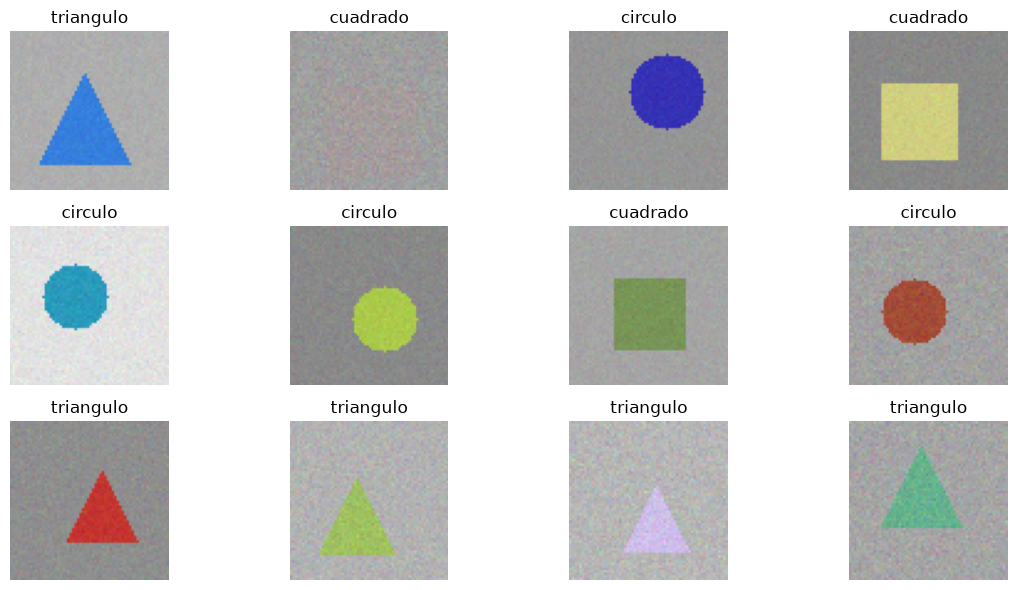

In [3]:
plt.figure(figsize=(12,6))
indices=np.random.choice(len(X),12,replace=False)
for i,idx in enumerate(indices):
    plt.subplot(3,4,i+1)
    plt.imshow(cv2.cvtColor(X[idx],cv2.COLOR_BGR2RGB))
    plt.title(nombres_clases[y[idx]])
    plt.axis("off")
plt.tight_layout(); plt.show()

### Preguntas rápidas
1. ¿Qué características visuales distinguen las clases?
2. ¿Es indispensable el color?
3. ¿Qué variaciones del entorno podrían dificultar la clasificación?

> **Nota sobre reproducibilidad.** Se fijaron las semillas (`np.random.seed`, `tf.random.set_seed`, `keras.utils.set_random_seed`) y se activó `enable_op_determinism()`. Aun así, TensorFlow en CPU conserva pequeñas fuentes de no determinismo (paralelismo entre hilos), así que al **volver a ejecutar** el notebook las cifras pueden variar unas décimas de punto, y los tiempos variar bastante. Las respuestas citan los valores de **la ejecución guardada en este archivo**; las conclusiones cualitativas se mantienen entre corridas.

#### Respuestas
1. **Características que distinguen las clases:** la **forma del contorno**. El círculo tiene un borde curvo sin esquinas; el cuadrado, cuatro esquinas y bordes horizontales y verticales; el triángulo, tres vértices y dos bordes inclinados. El tamaño, la posición y el color cambian dentro de cada clase, así que no sirven para distinguirlas.
2. **¿Es indispensable el color?** No. El color de cada pieza se elige al azar e **independientemente de la clase**, así que no aporta información sobre ella. Basta con que haya **contraste** entre la pieza y el fondo; la forma se reconocería igual en escala de grises. La red recibe 3 canales, pero tiene que aprender a ignorar el color.
3. **Variaciones del entorno que dificultan la clasificación:** iluminación no uniforme o sombras, poco contraste entre la pieza y el fondo (una pieza de color parecido al fondo casi desaparece), ruido del sensor, desenfoque o movimiento de la cinta, rotaciones y cambios de perspectiva, piezas parcialmente fuera del encuadre u ocluidas, fondos con textura o suciedad, y reflejos en piezas metálicas.

# Parte I — Convolución
## 4. Filtro diseñado manualmente
Un kernel para bordes verticales puede ser:
\[
\begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix}
\]
El resultado es un **mapa de características**.

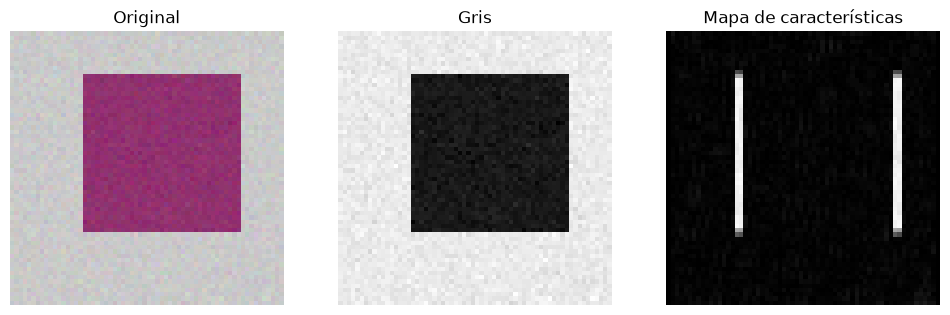

[[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]


In [4]:
idx=np.where(y==1)[0][0]
ejemplo_bgr=X[idx]
ejemplo_gris=cv2.cvtColor(ejemplo_bgr,cv2.COLOR_BGR2GRAY)
kernel=np.array([[-1,0,1],[-1,0,1],[-1,0,1]],dtype=np.float32)
mapa=cv2.filter2D(ejemplo_gris.astype(np.float32),-1,kernel)

plt.figure(figsize=(12,4))
for i,(img,t,cmap) in enumerate([(ejemplo_bgr,"Original",None),(ejemplo_gris,"Gris","gray"),(np.abs(mapa),"Mapa de características","gray")]):
    plt.subplot(1,3,i+1)
    if i==0: plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
    else: plt.imshow(img,cmap=cmap)
    plt.title(t); plt.axis("off")
plt.show()
print(kernel)

**Idea clave:** en OpenCV el ingeniero define el filtro. En una CNN, los valores del filtro se aprenden durante el entrenamiento.

### Preguntas
1. ¿Qué información resalta el kernel?
2. ¿Por qué la salida no se parece a la imagen original?
3. ¿Quién determina los valores del kernel en una CNN?

#### Respuestas
1. **Qué resalta el kernel:** los **bordes verticales**, es decir, los cambios de intensidad en dirección horizontal. Al aplicarlo al cuadrado solo aparecen sus lados izquierdo y derecho; los bordes horizontales y las zonas uniformes (el fondo y el interior de la pieza) dan casi cero.
2. **Por qué la salida no se parece a la imagen original:** el filtro no reproduce la intensidad del píxel sino una **diferencia** entre la columna derecha y la izquierda de cada vecindario 3×3, una especie de derivada horizontal. En regiones planas la diferencia es nula, así que el mapa solo conserva *dónde está* la característica buscada. Por eso se llama **mapa de características**: es una respuesta del filtro, no una imagen.
3. **Quién determina los valores del kernel en una CNN:** **el entrenamiento**. Los 9 valores (por canal) de cada kernel, más su sesgo, son parámetros que se inicializan al azar y se ajustan por retropropagación y descenso de gradiente para minimizar la pérdida. Nadie los diseña a mano.

## 5. Max Pooling

Antes: (64, 64)  Después: (32, 32)


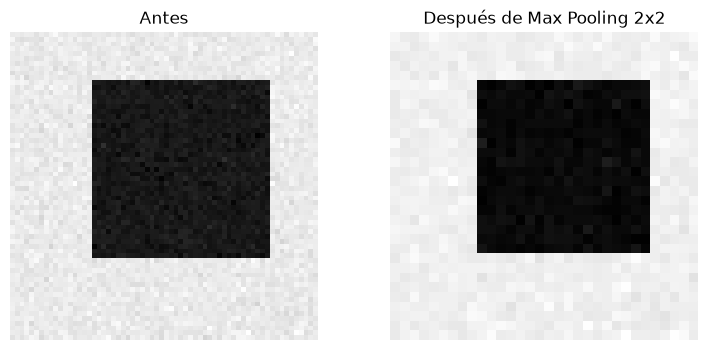

In [5]:
entrada=ejemplo_gris.astype(np.float32)[None,:,:,None]
salida=tf.nn.max_pool2d(entrada,ksize=2,strides=2,padding="VALID").numpy()[0,:,:,0]
print("Antes:",ejemplo_gris.shape," Después:",salida.shape)
plt.figure(figsize=(9,4))
plt.subplot(1,2,1); plt.imshow(ejemplo_gris,cmap="gray"); plt.title("Antes"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(salida,cmap="gray"); plt.title("Después de Max Pooling 2x2"); plt.axis("off")
plt.show()

Max Pooling conserva el máximo de cada ventana. Reduce dimensiones y costo computacional. No aprende pesos.

Ejemplo:
\[
\begin{bmatrix}1&7\\3&4\end{bmatrix}\rightarrow7
\]

# Parte II — Construcción y entrenamiento de una CNN
## 6. Separar datos y normalizar

In [6]:
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=0.50,random_state=42,stratify=y_temp)
X_train=X_train.astype("float32")/255.0
X_val=X_val.astype("float32")/255.0
X_test=X_test.astype("float32")/255.0
print("Train",X_train.shape," Val",X_val.shape," Test",X_test.shape)

Train (840, 64, 64, 3)  Val (180, 64, 64, 3)  Test (180, 64, 64, 3)


La normalización transforma los píxeles de 0–255 a 0–1, facilitando el entrenamiento.

## 7. Arquitectura CNN

In [7]:
# Re-fijar la semilla justo antes de crear el modelo: pesos iniciales reproducibles
keras.utils.set_random_seed(42)
model=keras.Sequential([
    layers.Input(shape=(IMG_SIZE,IMG_SIZE,3)),
    layers.Conv2D(16,(3,3),activation="relu",name="conv1"),
    layers.MaxPooling2D((2,2),name="pool1"),
    layers.Conv2D(32,(3,3),activation="relu",name="conv2"),
    layers.MaxPooling2D((2,2),name="pool2"),
    layers.Flatten(),
    layers.Dense(32,activation="relu"),
    layers.Dense(3,activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       200,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 205,923 (804.39 KB)

 Trainable params: 205,923 (804.39 KB)

 Non-trainable params: 0 (0.00 B)

### Interpretación por bloques
- `Conv2D(16)`: aprende 16 filtros 3×3.
- `MaxPooling2D`: reduce resolución espacial.
- `Conv2D(32)`: aprende representaciones de mayor nivel.
- `Flatten`: convierte los mapas en un vector.
- `Dense(32)`: combina características.
- `Dense(3, softmax)`: entrega probabilidades para tres clases.

### Preguntas
1. ¿Qué significa “16 filtros”?
2. ¿Por qué la salida tiene 3 neuronas?
3. ¿Qué representa Softmax?

#### Respuestas
1. **«16 filtros»** significa que la capa aprende **16 kernels distintos** de 3×3×3, cada uno con su sesgo, y cada uno produce su propio mapa de características. La salida de `conv1` tiene por eso 16 canales: (62, 62, 16). Cada filtro puede especializarse en un patrón distinto (bordes con cierta orientación, contraste pieza/fondo, etc.). Parámetros: 16·(3·3·3 + 1) = **448**.
2. **La salida tiene 3 neuronas** porque hay **3 clases** (círculo, cuadrado y triángulo). Cada neurona da la puntuación de una clase.
3. **Softmax** convierte las 3 puntuaciones en una **distribución de probabilidad**: valores entre 0 y 1 que suman 1. Cada valor se interpreta como la confianza del modelo en esa clase, y la predicción es la de mayor probabilidad.

## 8. Compilar y entrenar

In [8]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
early_stop=keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True)
history=model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=15,batch_size=32,callbacks=[early_stop],verbose=1)

Epoch 1/15


 1/27 ━━━━━━━━━━━━━━━━━━━━ 1:10 3s/step - accuracy: 0.3438 - loss: 1.1051

 2/27 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.2812 - loss: 1.1765

 3/27 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.3021 - loss: 1.1546

 5/27 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.3063 - loss: 1.1394

 8/27 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3320 - loss: 1.1200

... (184 outputs left out)

20/27 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9609 - loss: 0.1274

23/27 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9647 - loss: 0.1225

25/27 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9625 - loss: 0.1263

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.9607 - loss: 0.1297 - val_accuracy: 0.9389 - val_loss: 0.1639


Durante cada época ocurre:
$$
\text{Forward pass}\rightarrow\text{Pérdida}\rightarrow\text{Backpropagation}\rightarrow\text{Actualización de pesos}
$$
Los kernels convolucionales también se actualizan mediante retropropagación.

## 9. Curvas de aprendizaje

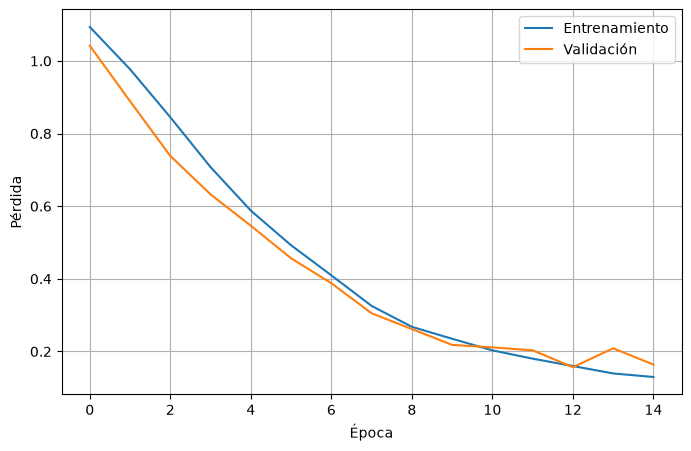

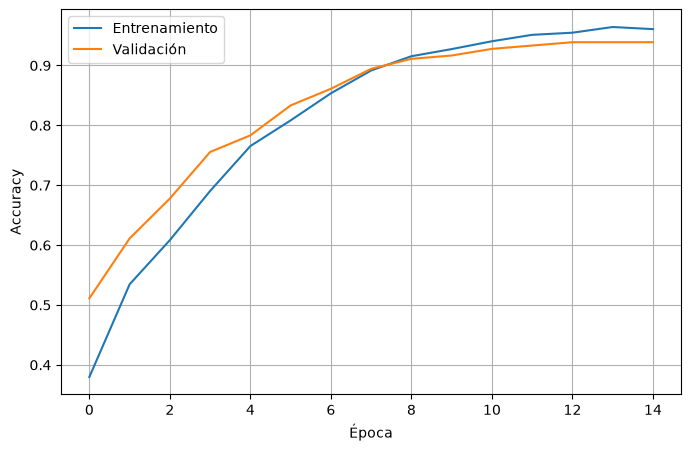

In [9]:
h=history.history
plt.figure(figsize=(8,5)); plt.plot(h["loss"],label="Entrenamiento"); plt.plot(h["val_loss"],label="Validación"); plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.legend(); plt.grid(); plt.show()
plt.figure(figsize=(8,5)); plt.plot(h["accuracy"],label="Entrenamiento"); plt.plot(h["val_accuracy"],label="Validación"); plt.xlabel("Época"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(); plt.show()

### Preguntas
1. ¿La pérdida disminuye?
2. ¿Validación acompaña a entrenamiento?
3. Si entrenamiento sube a 99 % y validación queda en 70 %, ¿qué problema sospecharía?

#### Respuestas
1. **¿La pérdida disminuye?** Sí. La de entrenamiento y la de validación bajan de forma sostenida desde ≈1.10, que es ln 3, la pérdida de adivinar al azar entre 3 clases, hasta valores cercanos a 0.1–0.2. El modelo aprende de verdad.
2. **¿Validación acompaña a entrenamiento?** Sí. Las dos curvas avanzan juntas y la de validación no se separa ni sube al final, así que **no hay sobreajuste visible**. El modelo usa las 15 épocas sin que `EarlyStopping` se active, señal de que todavía estaba mejorando cuando terminó el entrenamiento.
3. **Entrenamiento al 99 % y validación al 70 %** indica **sobreajuste (overfitting)**: el modelo memorizó los ejemplos de entrenamiento, incluido su ruido, y no generaliza. Remedios: más datos o *data augmentation*, regularización (Dropout, L2), un modelo con menos parámetros o detener antes el entrenamiento.

## 10. Evaluación con el conjunto de prueba

In [10]:
test_loss,test_acc=model.evaluate(X_test,y_test,verbose=0)
print(f"Loss prueba: {test_loss:.4f}")
print(f"Accuracy prueba: {test_acc:.4f}")

Loss prueba: 0.1955
Accuracy prueba: 0.9278


## 11. Matriz de confusión

Matriz de confusión (filas = real, columnas = predicción):
 [[58  1  1]
 [ 7 52  1]
 [ 3  0 57]]


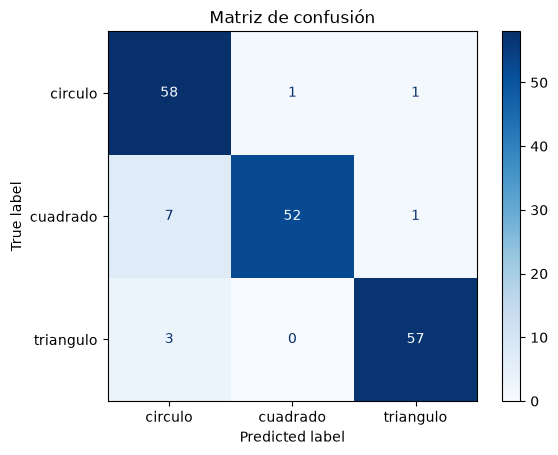

              precision    recall  f1-score   support

     circulo       0.85      0.97      0.91        60
    cuadrado       0.98      0.87      0.92        60
   triangulo       0.97      0.95      0.96        60

    accuracy                           0.93       180
   macro avg       0.93      0.93      0.93       180
weighted avg       0.93      0.93      0.93       180



In [11]:
probs=model.predict(X_test,verbose=0)
y_pred=np.argmax(probs,axis=1)
cm=confusion_matrix(y_test,y_pred)
print("Matriz de confusión (filas = real, columnas = predicción):\n",cm)
ConfusionMatrixDisplay(cm,display_labels=nombres_clases).plot(cmap="Blues")
plt.title("Matriz de confusión"); plt.show()
print(classification_report(y_test,y_pred,target_names=nombres_clases))

### Preguntas
1. ¿Qué representa la diagonal principal?
2. ¿Qué clases se confunden más?
3. ¿Por qué accuracy no muestra por sí sola el tipo de error?

#### Respuestas
1. **La diagonal principal** cuenta los **aciertos**: imágenes cuya clase predicha coincide con la real. Fuera de la diagonal están los errores. La fila indica la clase real y la columna, la predicha. En esta ejecución la diagonal es 58, 52 y 57, es decir, 167 de 180 aciertos (accuracy 0.928).
2. **Las clases que más se confunden** son **cuadrado → círculo**: 7 cuadrados se predijeron como círculos. Le sigue **triángulo → círculo**, con 3 casos. El círculo «absorbe» casi todos los errores: por eso tiene la *precision* más baja (0.85), mientras el cuadrado tiene el *recall* más bajo (0.87). Tiene sentido: con piezas pequeñas, ruido y una resolución que el pooling reduce a 14×14, las esquinas se suavizan y una silueta compacta empieza a parecerse a un círculo. Entre cuadrado y triángulo casi no hay confusión.
3. **La accuracy sola no muestra el tipo de error** porque resume todo en un número: dice *cuántos* errores hay, pero no *entre qué clases* ni *en qué dirección*. Una accuracy de 0.93 puede salir de errores repartidos o, como aquí, concentrados en un par de clases. En inspección importa saber qué pieza se clasifica mal, porque el costo de cada error no es el mismo; para eso están la matriz de confusión y las métricas por clase (precision, recall y F1).

## 12. Ejemplos de predicción

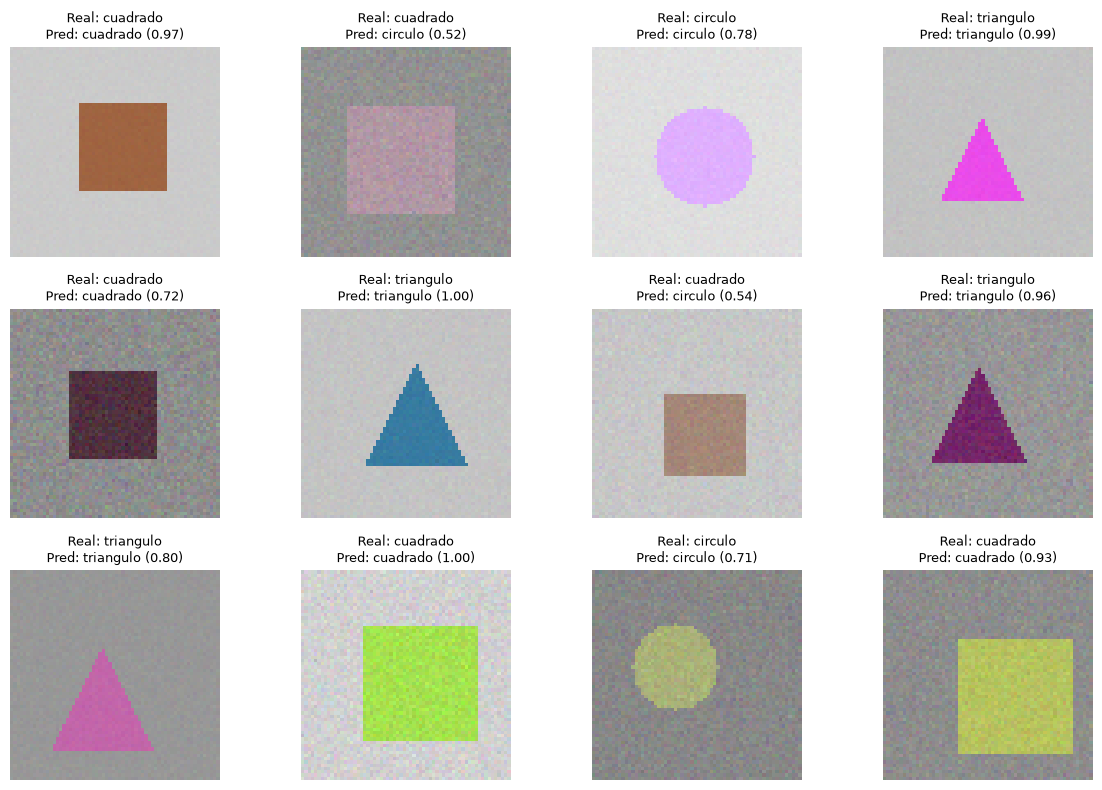

In [12]:
plt.figure(figsize=(12,8))
indices=np.random.choice(len(X_test),12,replace=False)
for i,idx in enumerate(indices):
    plt.subplot(3,4,i+1)
    plt.imshow(X_test[idx][...,::-1])
    pred=y_pred[idx]; real=y_test[idx]; conf=probs[idx][pred]
    plt.title(f"Real: {nombres_clases[real]}\nPred: {nombres_clases[pred]} ({conf:.2f})",fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

## 13. Visualizar mapas de características aprendidos

Shape: (1, 62, 62, 16)


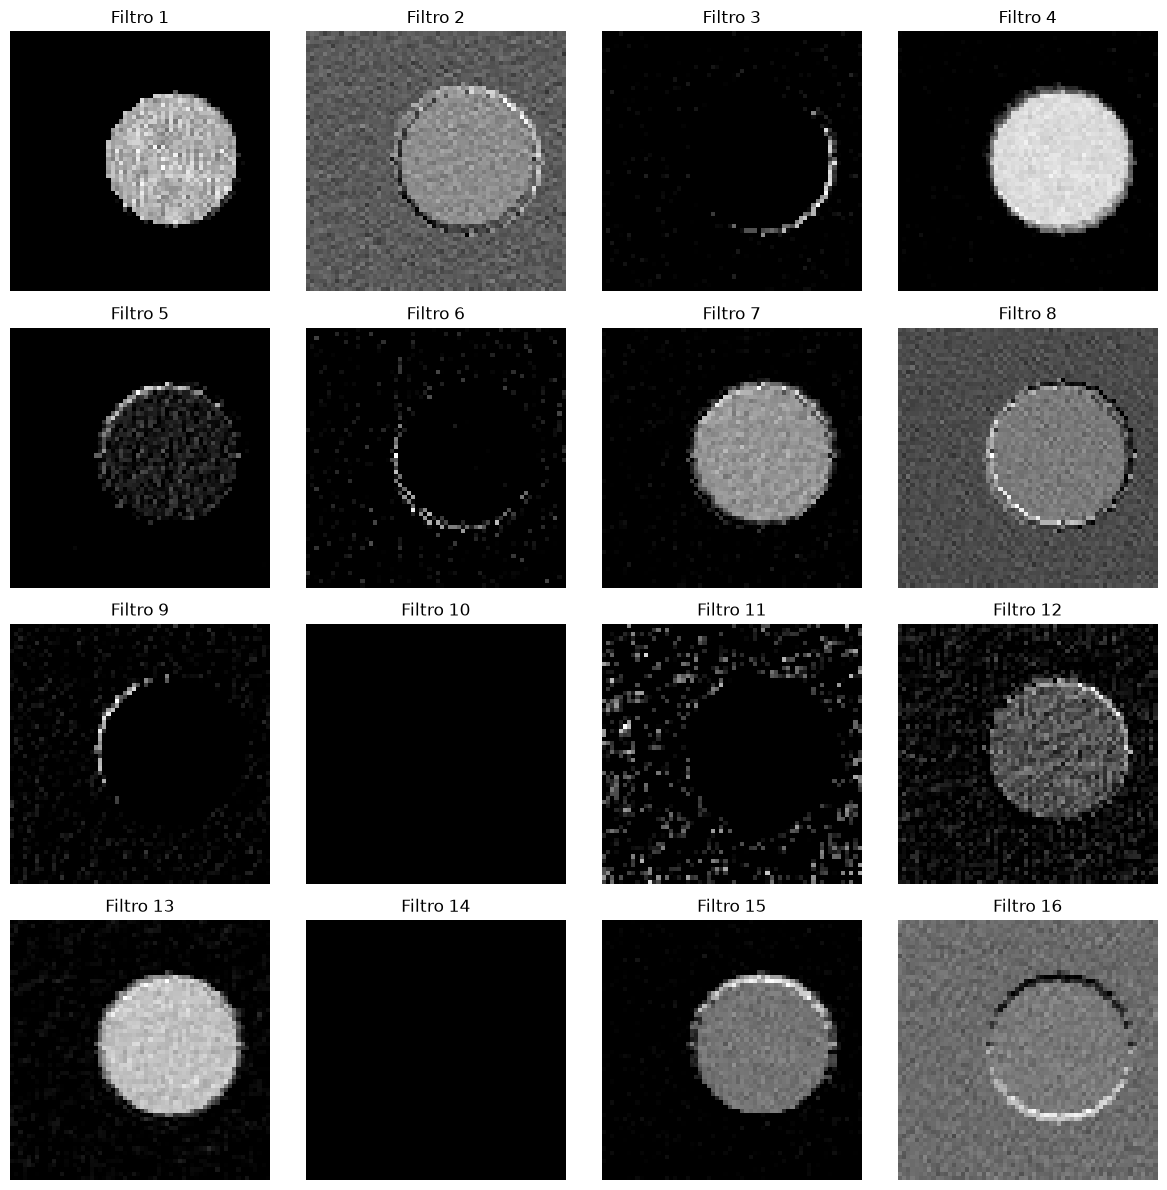

In [13]:
modelo_features=keras.Model(inputs=model.inputs,outputs=model.get_layer("conv1").output)
muestra=X_test[0:1]
feature_maps=modelo_features.predict(muestra,verbose=0)
print("Shape:",feature_maps.shape)
plt.figure(figsize=(12,12))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(feature_maps[0,:,:,i],cmap="gray")
    plt.title(f"Filtro {i+1}"); plt.axis("off")
plt.tight_layout(); plt.show()

Las primeras capas suelen responder a estructuras como bordes, orientaciones, contrastes y texturas. No es necesario que cada filtro tenga una interpretación humana simple.

### Preguntas
1. ¿Todos los filtros responden igual?
2. ¿Cuáles resaltan bordes o regiones particulares?
3. ¿Qué diferencia hay entre estos filtros y el kernel manual usado al inicio?

#### Respuestas
(La muestra `X_test[0]` es un círculo.)
1. **¿Todos los filtros responden igual?** No. Cada filtro produce un mapa distinto: unos **resaltan la pieza completa** como región brillante (filtros 1, 4, 7 y 13), otros responden **solo a una parte del contorno**, otros combinan fondo, pieza y borde, y el 11 responde casi solo al **ruido del fondo**. Los filtros 10 y 14 quedan **completamente apagados**: tras ReLU toda su salida es 0 para esta imagen. Pueden ser filtros especializados en patrones que aquí no aparecen, o filtros «muertos».
2. **Filtros que resaltan bordes o regiones:** los filtros 3, 5, 6 y 9 se activan **solo en arcos del contorno** con una orientación concreta: el 3 en el borde derecho e inferior, el 5 en el superior, el 6 en el inferior izquierdo y el 9 en el izquierdo. Son detectores de borde orientados, como el kernel manual pero aprendidos. Los filtros 2, 8 y 16 producen un efecto de **relieve**, con un lado del contorno claro y el opuesto oscuro, igual que un gradiente direccional. Los filtros 12 y 15 combinan región y borde superior. Los filtros 1, 4, 7 y 13 detectan la **región** de la pieza por contraste de color con el fondo.
3. **Diferencia con el kernel manual:** el kernel del inicio fue **diseñado** para una sola tarea (bordes verticales), es fijo, trabaja sobre la imagen en gris y su utilidad para clasificar no está garantizada. Los filtros de la CNN son **aprendidos**: se ajustaron automáticamente para reducir el error de clasificación, operan sobre los 3 canales a la vez, son 16 en paralelo y cubren varias orientaciones y tipos de patrón. Además, la siguiente capa los combina en características de mayor nivel.

## 14. Ver los kernels aprendidos

Kernels: (3, 3, 3, 16)  Sesgos: (16,)


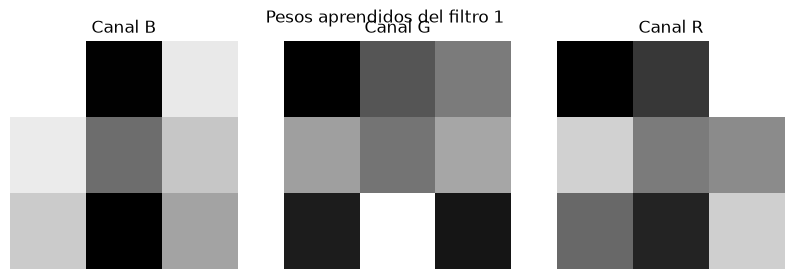

In [14]:
pesos,sesgos=model.get_layer("conv1").get_weights()
print("Kernels:",pesos.shape," Sesgos:",sesgos.shape)
filtro=pesos[:,:,:,0]
plt.figure(figsize=(10,3))
for i,t in enumerate(["Canal B","Canal G","Canal R"]):
    plt.subplot(1,3,i+1); plt.imshow(filtro[:,:,i],cmap="gray"); plt.title(t); plt.axis("off")
plt.suptitle("Pesos aprendidos del filtro 1"); plt.show()

# Parte III — Clase taller
## 15. Banco de preguntas conceptuales

1. ¿Qué significa que una imagen sea un tensor 64×64×3?
2. ¿Qué es un kernel convolucional?
3. ¿Qué es un mapa de características?
4. ¿Qué diferencia existe entre un filtro manual de OpenCV y un filtro de una CNN?
5. ¿Qué función cumple ReLU?
6. ¿Qué hace Max Pooling?
7. ¿Por qué una CNN conserva mejor la estructura espacial que una MLP que aplana todos los píxeles?
8. ¿Qué representa cada neurona de salida?
9. ¿Qué representa Softmax?
10. ¿Cuál es la diferencia entre clasificación y detección de objetos?
11. ¿Qué indica una fuerte diferencia entre accuracy de entrenamiento y validación?
12. ¿Por qué se reserva un conjunto de prueba?
13. ¿Qué efecto puede tener aumentar la cantidad de filtros?
14. ¿Qué puede ocurrir si se aplica demasiado pooling?
15. ¿Por qué una CNN puede manejar mejor variabilidad visual que reglas manuales?


#### Respuestas al banco de preguntas

1. **Imagen como tensor 64×64×3:** es un arreglo de 3 dimensiones con 64 filas (alto), 64 columnas (ancho) y 3 canales de color (B, G y R en OpenCV). Cada elemento es la intensidad de un canal en un píxel: 0–255, o 0–1 tras normalizar. En total son 12 288 números.
2. **Kernel convolucional:** una pequeña matriz de pesos (aquí 3×3 por canal) que se desliza sobre la imagen. En cada posición se multiplica elemento a elemento con el vecindario, se suma y se agrega un sesgo. El kernel define *qué patrón* busca el filtro.
3. **Mapa de características:** la salida de aplicar un kernel a toda la imagen. Es una matriz 2D cuyos valores altos indican *dónde* aparece el patrón que el kernel detecta. Una capa con N filtros produce N mapas.
4. **Filtro manual de OpenCV frente a filtro de CNN:** el manual lo **diseña el ingeniero** con valores fijos y un propósito conocido (Sobel, por ejemplo). El de la CNN lo **aprende la red** a partir de los datos mediante retropropagación, optimizando directamente el objetivo (clasificar), y puede capturar patrones que no se habrían diseñado a mano.
5. **ReLU:** f(x) = max(0, x). Introduce **no linealidad**, sin la cual una pila de capas equivaldría a una sola transformación lineal. Además anula las respuestas negativas, dejando solo las activaciones donde el patrón está presente, y es barata de calcular y de derivar, lo que mitiga el desvanecimiento del gradiente.
6. **Max Pooling:** divide el mapa en ventanas (2×2) y conserva el máximo de cada una. Reduce la resolución a la mitad por eje, lo que baja el cómputo y los parámetros posteriores, aporta cierta **tolerancia a pequeños desplazamientos** y amplía el campo receptivo de las capas siguientes. No tiene pesos que aprender.
7. **Por qué la CNN conserva mejor la estructura espacial que una MLP:** la MLP aplana los 12 288 valores en un vector y pierde la noción de vecindad: un píxel y su vecino son entradas independientes, y cada neurona se conecta a todos los píxeles, lo que da muchísimos parámetros. La CNN aplica **conexiones locales** (cada salida mira un vecindario) con **pesos compartidos** (el mismo kernel en toda la imagen). Así explota que los píxeles cercanos están relacionados, detecta un patrón sin importar dónde esté (equivarianza a traslación) y usa muchos menos parámetros por capa convolucional.
8. **Cada neurona de salida** representa **una clase**: círculo, cuadrado o triángulo. Su valor tras Softmax es la probabilidad estimada de que la imagen pertenezca a esa clase.
9. **Softmax:** la función softmax(zᵢ) = e^{zᵢ} / Σⱼ e^{zⱼ} transforma las puntuaciones (logits) en una distribución de probabilidad que suma 1. Junto con la entropía cruzada permite entrenar la clasificación multiclase.
10. **Clasificación frente a detección:** la **clasificación** asigna **una etiqueta a toda la imagen** y supone una pieza por imagen, como en esta práctica. La **detección** (YOLO, por ejemplo) encuentra **varios objetos** en la misma imagen y, para cada uno, entrega su **ubicación** (caja delimitadora), su **clase** y una **confianza**.
11. **Gran diferencia entre accuracy de entrenamiento y de validación:** indica **sobreajuste**. El modelo memoriza el conjunto de entrenamiento y no generaliza a datos nuevos.
12. **Por qué se reserva un conjunto de prueba:** el de validación ya se usó para tomar decisiones (cuándo detener con `EarlyStopping`, qué arquitectura elegir), así que su resultado queda sesgado a favor del modelo. El de **prueba** se usa **una sola vez al final** para estimar sin sesgo el desempeño con datos nunca vistos, como en la estación real.
13. **Efecto de aumentar la cantidad de filtros:** la capa puede aprender **más patrones distintos**, lo que da más capacidad de representación y, en general, mejor desempeño en problemas complejos. A cambio crecen los parámetros, la memoria y el tiempo de cómputo, y sube el riesgo de sobreajuste si hay pocos datos. Las ganancias son decrecientes. En el Desafío 1 se cuantifica: duplicar los filtros duplica los parámetros, en buena parte porque crece la capa densa tras `Flatten`.
14. **Demasiado pooling:** cada pooling descarta información espacial. Si se aplica en exceso, los mapas quedan diminutos (1×1 o 2×2) y se pierden detalles finos como esquinas o vértices, justo lo que distingue un cuadrado de un círculo. Sobrevienen subajuste y confusiones entre clases parecidas, y con piezas pequeñas la característica puede desaparecer.
15. **Por qué una CNN maneja mejor la variabilidad visual que las reglas manuales:** las reglas manuales («si tiene 4 esquinas es un cuadrado», umbrales fijos) son frágiles: fallan con ruido, cambios de iluminación, de tamaño, de posición o de color, y cada caso nuevo exige reprogramar. La CNN **aprende de ejemplos** que ya contienen esa variabilidad, y sus filtros compartidos más el pooling dan robustez a traslaciones y pequeñas deformaciones. Para adaptarla a una condición nueva basta con añadir datos representativos y volver a entrenar.

## 16. Desafío 1 — Reducir la cantidad de filtros
Cambiar `16→8` y `32→16`. Comparar:
- parámetros;
- accuracy de prueba;
- tiempo de entrenamiento.

**Pregunta:** ¿una red más grande siempre es mejor?

### Desarrollo del Desafío 1

Para que la comparación sea justa, **ambas arquitecturas se entrenan en las mismas condiciones**: mismos datos, mismo optimizador, mismo `EarlyStopping`, mismo tamaño de lote y máximo de 15 épocas.
Como el resultado de una red depende de la inicialización aleatoria de los pesos, cada arquitectura se entrena con **3 semillas distintas** y se reporta la media y la desviación estándar. Así se evita sacar conclusiones de una sola corrida afortunada (o desafortunada).

In [15]:
import time
import pandas as pd

def construir_cnn(f1, f2, nombre):
    """Misma arquitectura de la sección 7, con la cantidad de filtros como parámetro."""
    return keras.Sequential([
        layers.Input(shape=(IMG_SIZE,IMG_SIZE,3)),
        layers.Conv2D(f1,(3,3),activation="relu",name="conv1"),
        layers.MaxPooling2D((2,2),name="pool1"),
        layers.Conv2D(f2,(3,3),activation="relu",name="conv2"),
        layers.MaxPooling2D((2,2),name="pool2"),
        layers.Flatten(),
        layers.Dense(32,activation="relu"),
        layers.Dense(3,activation="softmax")
    ], name=f"cnn_{f1}_{f2}")

def entrenar_y_evaluar(f1, f2, nombre, semilla):
    keras.utils.set_random_seed(semilla)          # fija numpy, random y TensorFlow
    m = construir_cnn(f1, f2, nombre)
    m.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True)
    t0 = time.perf_counter()
    hist = m.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=15,batch_size=32,
                 callbacks=[es],verbose=0)
    t_entr = time.perf_counter() - t0
    loss, acc = m.evaluate(X_test,y_test,verbose=0)
    epocas = len(hist.history["loss"])
    return m, hist, {"Modelo": nombre, "Semilla": semilla, "Parámetros": m.count_params(),
                     "Épocas": epocas, "Tiempo total (s)": t_entr, "Tiempo/época (s)": t_entr/epocas,
                     "Loss prueba": loss, "Accuracy prueba": acc}

In [16]:
# Parámetros de cada capa en ambas arquitecturas (no requiere entrenar)
for f1, f2, nombre in [(16,32,"CNN base (16/32)"), (8,16,"CNN reducida (8/16)")]:
    m = construir_cnn(f1, f2, "tmp")
    print(f"\n{nombre}  —  total: {m.count_params():,} parámetros")
    for capa in m.layers:
        print(f"   {capa.name:10s} salida {str(capa.output.shape):20s} parámetros {capa.count_params():>9,}")


CNN base (16/32)  —  total: 205,923 parámetros


   conv1      salida (None, 62, 62, 16)   parámetros       448
   pool1      salida (None, 31, 31, 16)   parámetros         0
   conv2      salida (None, 29, 29, 32)   parámetros     4,640
   pool2      salida (None, 14, 14, 32)   parámetros         0
   flatten_1  salida (None, 6272)         parámetros         0
   dense_2    salida (None, 32)           parámetros   200,736
   dense_3    salida (None, 3)            parámetros        99

CNN reducida (8/16)  —  total: 101,875 parámetros
   conv1      salida (None, 62, 62, 8)    parámetros       224
   pool1      salida (None, 31, 31, 8)    parámetros         0
   conv2      salida (None, 29, 29, 16)   parámetros     1,168
   pool2      salida (None, 14, 14, 16)   parámetros         0
   flatten_2  salida (None, 3136)         parámetros         0
   dense_4    salida (None, 32)           parámetros   100,384
   dense_5    salida (None, 3)            parámetros        99


In [17]:
configs = [(16,32,"CNN base (16/32)"), (8,16,"CNN reducida (8/16)")]
semillas = [0, 1, 2]
filas, modelos, historiales = [], {}, {}
for f1, f2, nombre in configs:
    for s in semillas:
        m, hist, r = entrenar_y_evaluar(f1, f2, nombre, s)
        filas.append(r)
        print(f"{nombre:22s} semilla {s}: acc={r['Accuracy prueba']:.4f}  épocas={r['Épocas']:2d}  "
              f"tiempo={r['Tiempo total (s)']:.1f}s")
        if s == semillas[0]:
            modelos[nombre], historiales[nombre] = m, hist.history

df = pd.DataFrame(filas)
df

CNN base (16/32)       semilla 0: acc=0.9444  épocas=15  tiempo=16.0s


CNN base (16/32)       semilla 1: acc=0.8889  épocas=15  tiempo=18.7s


CNN base (16/32)       semilla 2: acc=0.9278  épocas=15  tiempo=15.7s


CNN reducida (8/16)    semilla 0: acc=0.9333  épocas=15  tiempo=16.5s


CNN reducida (8/16)    semilla 1: acc=0.8833  épocas=15  tiempo=16.4s


CNN reducida (8/16)    semilla 2: acc=0.8611  épocas=15  tiempo=14.5s


,Modelo,Semilla,Parámetros,Épocas,Tiempo total (s),Tiempo/época (s),Loss prueba,Accuracy prueba
0,CNN base (16/32),0,205923,15,16.048740,1.069916,0.156288,0.944444
1,CNN base (16/32),1,205923,15,18.708339,1.247223,0.339644,0.888889
2,CNN base (16/32),2,205923,15,15.696360,1.046424,0.222363,0.927778
3,CNN reducida (8/16),0,101875,15,16.533289,1.102219,0.198719,0.933333
4,CNN reducida (8/16),1,101875,15,16.356111,1.090407,0.363510,0.883333
5,CNN reducida (8/16),2,101875,15,14.516562,0.967771,0.346902,0.861111


In [18]:
resumen = df.groupby("Modelo", sort=False).agg(
    Parámetros=("Parámetros","first"),
    Acc_media=("Accuracy prueba","mean"), Acc_std=("Accuracy prueba","std"),
    Loss_media=("Loss prueba","mean"),
    Épocas_media=("Épocas","mean"),
    Tiempo_total_s=("Tiempo total (s)","mean"),
    Tiempo_época_s=("Tiempo/época (s)","mean"))
base, red = resumen.loc["CNN base (16/32)"], resumen.loc["CNN reducida (8/16)"]
print(f"Reducción de parámetros: {1-red['Parámetros']/base['Parámetros']:.1%}")
print(f"Reducción del tiempo por época: {1-red['Tiempo_época_s']/base['Tiempo_época_s']:.1%}")
print(f"Diferencia de accuracy media (reducida - base): {red['Acc_media']-base['Acc_media']:+.4f}")
resumen.round(4)

Reducción de parámetros: 50.5%
Reducción del tiempo por época: 6.0%
Diferencia de accuracy media (reducida - base): -0.0278


,Parámetros,Acc_media,Acc_std,Loss_media,Épocas_media,Tiempo_total_s,Tiempo_época_s
Modelo,,,,,,,
CNN base (16/32),205923,0.9204,0.0285,0.2394,15.0,16.8178,1.1212
CNN reducida (8/16),101875,0.8926,0.0370,0.3030,15.0,15.8020,1.0535


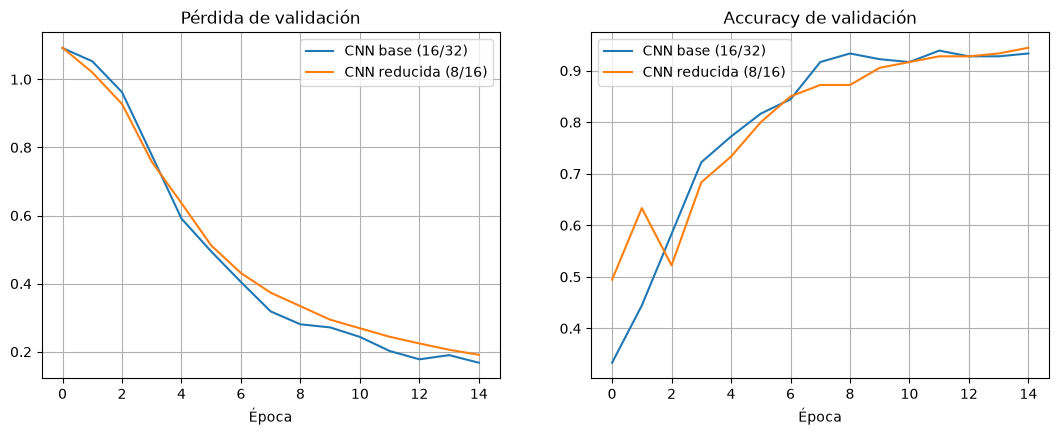

Matriz de confusión CNN reducida (filas = real):
 [[58  1  1]
 [ 9 51  0]
 [ 1  0 59]]


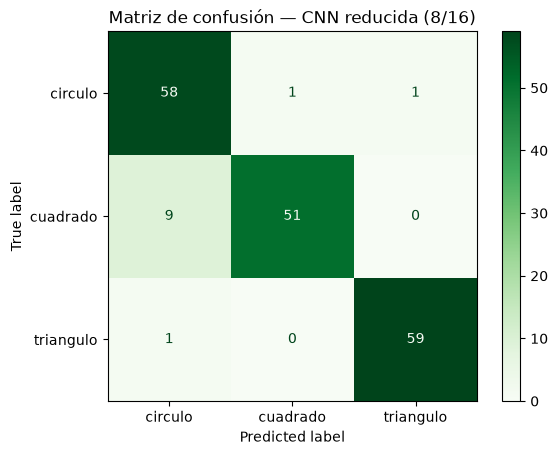

In [19]:
# Curvas de validación (semilla 0) y matriz de confusión del modelo reducido
fig, ax = plt.subplots(1,2,figsize=(13,4.5))
for nombre, h in historiales.items():
    ax[0].plot(h["val_loss"],label=nombre); ax[1].plot(h["val_accuracy"],label=nombre)
ax[0].set_title("Pérdida de validación"); ax[1].set_title("Accuracy de validación")
for a in ax: a.set_xlabel("Época"); a.grid(); a.legend()
plt.show()

m_red = modelos["CNN reducida (8/16)"]
y_pred_red = np.argmax(m_red.predict(X_test,verbose=0),axis=1)
cm_red = confusion_matrix(y_test,y_pred_red)
print("Matriz de confusión CNN reducida (filas = real):\n", cm_red)
ConfusionMatrixDisplay(cm_red,display_labels=nombres_clases).plot(cmap="Greens")
plt.title("Matriz de confusión — CNN reducida (8/16)"); plt.show()

### Análisis del Desafío 1

**Parámetros.** La red reducida tiene **101 875** parámetros frente a **205 923** de la base, **50.5 % menos**. Lo interesante es *dónde* está el ahorro:

| Capa | Base (16/32) | Reducida (8/16) |
|---|---:|---:|
| `conv1` | 448 | 224 |
| `conv2` | 4 640 | 1 168 |
| `Dense(32)` tras `Flatten` | **200 736** | **100 384** |
| `Dense(3)` | 99 | 99 |

Más del **97 %** de los parámetros está en la capa densa que sigue a `Flatten`, y esa capa depende del **número de canales** que sale de `conv2` (14·14·32 = 6272 entradas frente a 14·14·16 = 3136). Las convoluciones son baratas en parámetros porque comparten pesos; lo que encarece la red es aplanar mapas grandes.

**Accuracy de prueba (media ± desviación en 3 semillas).** Base: **0.920 ± 0.029**. Reducida: **0.893 ± 0.037**. La red reducida pierde unos **2.8 puntos porcentuales** en promedio. Con la misma semilla la base supera a la reducida en las 3 corridas, aunque en la semilla 1 la diferencia es mínima (0.889 frente a 0.883). Las curvas de validación muestran que la red pequeña **aprende más lento**: su pérdida de validación queda por encima de la base desde la época 4. Ninguna de las dos activó `EarlyStopping` (las 6 corridas llegaron a las 15 épocas), así que con el límite de 15 épocas la red pequeña queda más lejos de su punto de convergencia.

En la matriz de confusión, la reducida comete el **mismo tipo de error** que la base: 9 cuadrados se confunden con círculos. Con 8 filtros en lugar de 16 hay menos detectores disponibles para capturar las esquinas, que son la pista decisiva.

**Tiempo de entrenamiento.** En esta ejecución la reducida tardó ≈**1.05 s/época** frente a ≈**1.12 s/época** de la base, solo un **6 % menos**. En ejecuciones anteriores de prueba la diferencia llegó al 20–40 %. Dos conclusiones:
- el ahorro de tiempo es **mucho menor que la reducción de parámetros**, porque en CPU el tiempo lo dominan las convoluciones sobre mapas de 62×62 y 29×29, la retropropagación a través de ellas y la gestión de lotes, no el número de pesos de la capa densa (una multiplicación matriz-vector de 6272×32 es barata);
- los tiempos medidos en CPU **varían mucho** de una corrida a otra por carga del sistema, caché y compilación del grafo en la primera época. Deben leerse como tendencia, no como valor exacto.

**¿Una red más grande siempre es mejor?** **No.** Aquí la red más grande fue algo más precisa, pero:
- duplicó parámetros y memoria a cambio de unos 2.8 puntos, una ganancia del mismo orden que la variación entre semillas (desviación de 3–4 puntos);
- más capacidad solo ayuda mientras el problema la necesite y haya datos suficientes. Con pocos datos, una red grande tiende a **sobreajustar**, y en un problema simple el exceso de filtros no aporta;
- en un sistema mecatrónico embebido (una cámara con microcontrolador o una Raspberry Pi en la línea), un modelo con la mitad de parámetros y menor latencia puede ser **la mejor opción de ingeniería** si cumple la exactitud exigida.

La elección correcta es el modelo **más pequeño que alcance el desempeño requerido**. Si el requisito fuera, por ejemplo, el 90 %, convendría probar la red reducida con más épocas antes de descartarla, ya que su curva de validación seguía mejorando al final.

## 17. Desafío 2 — Eliminar una capa de pooling
Eliminar `pool1` o `pool2` y observar:
- dimensiones internas;
- número de parámetros;
- desempeño;
- costo computacional.

**Pregunta:** ¿qué costo tiene conservar mapas de mayor resolución?

## 18. Desafío 3 — Aumentar la dificultad
Modificar `crear_imagen()` para introducir:
- más ruido;
- menor contraste;
- piezas pequeñas;
- desplazamientos mayores;
- rotaciones;
- fondo más variable.

Analizar qué cambio afecta más al modelo.

## 19. Desafío 4 — Añadir una cuarta clase: arandela
Crear un círculo exterior y otro interior del color del fondo. Luego modificar:
- `nombres_clases`;
- generación de datos;
- salida de 3 a 4 neuronas.

**Pregunta:** ¿por qué la capa final debe cambiar?

## 20. Desafío 5 — Comparar con una MLP
Construir una red sin convoluciones:
\[
64\times64\times3\rightarrow Flatten\rightarrow Dense\rightarrow Dense\rightarrow Salida
\]
Comparar parámetros, accuracy y robustez.

**Pregunta central:** ¿qué ventaja aporta la convolución cuando la entrada es una imagen?

In [20]:
# Celda opcional para el Desafío 5
# modelo_mlp = keras.Sequential([
#     layers.Input(shape=(IMG_SIZE,IMG_SIZE,3)),
#     layers.Flatten(),
#     layers.Dense(128,activation="relu"),
#     layers.Dense(64,activation="relu"),
#     layers.Dense(3,activation="softmax")
# ])
# modelo_mlp.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
# modelo_mlp.summary()

# 21. Actividad integradora del taller

Una estación de inspección debe reconocer tres tipos de piezas que llegan individualmente frente a una cámara.

El estudiante deberá:
1. ejecutar la CNN base;
2. interpretar curvas de aprendizaje;
3. interpretar la matriz de confusión;
4. visualizar feature maps;
5. seleccionar un desafío;
6. modificar datos o arquitectura;
7. comparar resultados;
8. justificar técnicamente las diferencias.

### Tabla sugerida
| Modelo | Parámetros | Accuracy prueba | Observación |
|---|---:|---:|---|
| CNN base | ... | ... | ... |
| Modificado | ... | ... | ... |

La conclusión debe explicar **por qué** la modificación mejora o empeora el desempeño, no solamente cuál accuracy es mayor.


### Desarrollo de la actividad integradora

1. **CNN base ejecutada** (secciones 6 a 14): accuracy de prueba **0.928** en la corrida principal.
2. **Curvas de aprendizaje:** la pérdida baja de ≈1.10 a ≈0.15 y la validación acompaña al entrenamiento, sin sobreajuste. El modelo seguía mejorando al llegar a la época 15.
3. **Matriz de confusión:** el error dominante es **cuadrado → círculo** (7 casos), seguido de triángulo → círculo (3). Entre cuadrado y triángulo casi no hay confusión.
4. **Feature maps:** `conv1` aprende detectores de borde orientados (filtros 3, 5, 6 y 9), filtros de relieve o gradiente (2, 8 y 16), detectores de región por contraste pieza/fondo (1, 4, 7 y 13) y dos filtros inactivos para esta muestra (10 y 14).
5. **Desafío elegido:** **Desafío 1, reducir los filtros** de 16/32 a 8/16.
6. **Modificación:** se parametrizó la arquitectura (`construir_cnn(f1, f2)`) y se entrenaron ambas versiones en idénticas condiciones con 3 semillas.
7. **Comparación de resultados:**

| Modelo | Parámetros | Accuracy prueba (media ± std, 3 semillas) | Tiempo/época | Observación |
|---|---:|---:|---:|---|
| CNN base (16/32) | 205 923 | 0.920 ± 0.029 | ≈1.12 s | Converge más rápido; error principal cuadrado → círculo. |
| CNN reducida (8/16) | 101 875 | 0.893 ± 0.037 | ≈1.05 s | −50.5 % de parámetros; aprende más lento y pierde ≈2.8 pts; mismo patrón de error. |

8. **Justificación técnica de las diferencias.**

   La red reducida **empeora levemente** por una razón de **capacidad de representación**. Con 8 filtros en `conv1` y 16 en `conv2` hay la mitad de detectores de patrones en cada nivel. Distinguir un cuadrado de un círculo depende de detalles finos (esquinas y bordes rectos con orientaciones concretas), y con menos filtros la red tiene menos combinaciones disponibles para codificarlos. Por eso necesita más épocas para alcanzar el mismo nivel, y dentro del límite de 15 épocas queda por debajo. Su pérdida de validación es mayor durante todo el entrenamiento, no solo al final.

   La reducción de **parámetros** (≈50 %) es mucho mayor que la de **exactitud** (≈3 %). Casi todos los pesos de la red están en la capa densa tras `Flatten`, cuyo tamaño es proporcional al número de canales de `conv2`. Al reducir filtros se ahorran sobre todo pesos densos y no capacidad convolucional. Esto muestra que en esta arquitectura el «tamaño» de la red lo determina el aplanado, y que hay mejores formas de reducirla sin perder detectores, por ejemplo `GlobalAveragePooling2D` en lugar de `Flatten`.

   El **tiempo** baja menos que los parámetros porque el costo de cómputo lo dominan las convoluciones sobre mapas grandes, no el número de pesos.

   **Conclusión:** para la estación de inspección, la red base es preferible si se prioriza la exactitud. La reducida es una alternativa válida para hardware limitado, siempre que se compense con más épocas de entrenamiento y se verifique que cumple el umbral de exactitud exigido. Una red más grande no es automáticamente mejor: hay que equilibrar exactitud, costo computacional y riesgo de sobreajuste.

# 22. Síntesis conceptual

### Visión clásica
$$
\text{Imagen}\rightarrow\text{filtro diseñado}\rightarrow\text{características definidas}\rightarrow\text{reglas}
$$

### CNN
$$
\text{Imagen}\rightarrow\text{filtros aprendidos}\rightarrow\text{feature maps}\rightarrow\text{clasificación}
$$

La idea central es que la CNN **aprende representaciones útiles directamente de los datos**.

El siguiente paso de la unidad puede introducir detección de objetos con un modelo preentrenado:
$$
\text{Imagen}\rightarrow\text{localización} + \text{clase} + \text{confianza}
$$


## Referencias sugeridas
- Géron, A. *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd ed.
- Goodfellow, I., Bengio, Y. & Courville, A. *Deep Learning*. MIT Press.
- Szeliski, R. *Computer Vision: Algorithms and Applications*, 2nd ed.
- TensorFlow/Keras Documentation — Convolutional Neural Networks.
